# Preparing the data, step by step

This notebook rebuilds the clean dataset of the thesis from the two raw files, one small step at a
time, and explains every idea the first time it appears. At the end it checks that what we built
here is identical to what the pipeline script (`src/thesis/data/build_panel.py`) produces.

**What we are building.** One table with one row per stock and trading day (40 stocks, about
2,900 days each). Every row carries the day's return and the day's *true variance*. That true
variance is the number every forecast in the thesis will be judged against, so two decisions
about how to measure it matter a lot:

- **Decision 2:** which hours of the day should the true variance cover?
- **Decision 3:** what to do on the 459 evenings when a company reported earnings right after the close?

**The route.**
1. The two raw files
2. Returns, and why "adjusted" prices matter
3. Cutting a day into overnight and intraday
4. Joining the two files
5. Decision 2
6. Decision 3
7. The finished truth and the market variables
8. Is it the same as the pipeline?
9. Features and the no-look-ahead rule
10. Glossary

**How to use it.** Run the cells from the top (Kernel: Python 3, package `ipykernel` installed).
Every chart is also saved to `notes/figures/`, and the last cell saves the key numbers to a JSON
file that the PDF explainer reads. Nothing here changes your data or your settings.

In [6]:
import json
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from thesis.paths import FEATURES, FLAGS, PANEL, RAW_VOLARE, RAW_YAHOO, load_config

cfg = load_config()
FIG = ROOT / "notes" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
numbers = {}   # key figures, saved at the end for the PDF explainer

# chart style: three colours checked for colour-blind safety, quiet solid grid, dark text
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({"font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10, "figure.dpi": 110,
                     "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE})


def tidy(ax, title, subtitle=None):
    ax.set_title(title, loc="left", color=INK, fontsize=11.5, fontweight="bold", pad=26 if subtitle else 8)
    if subtitle:
        ax.annotate(subtitle, xy=(0, 1), xycoords="axes fraction", xytext=(0, 8), textcoords="offset points",
                    color=MUTED, fontsize=9.5)
    ax.grid(color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED, length=0)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")


def ann_vol(variance):
    # daily variance -> yearly volatility in percent (252 trading days in a year)
    return 100 * np.sqrt(252 * variance)


print("settings in config.yaml ->", cfg["target"])

settings in config.yaml -> {'intraday_measure': 'rv5_ss', 'add_overnight': True, 'dividend_adjust_overnight': True, 'earnings_days': 'medrv5', 'log_target': True}


---
## 1. The two raw files

**VOLARE** (`data/raw/volare/realized_variance_stocks.csv`) is an open library built from
five-minute prices. One row is one stock on one trading day, and the row already contains the
day's *realised variance*: the sum of the squared five-minute returns between 09:30 and 16:05.
It also has the day's opening and closing price as traded, the volume and the number of trades.

**Yahoo Finance** (`data/raw/yahoo_prices.csv`) has one row per symbol and day with the open,
close, and an *adjusted* close, plus the dividend paid and any stock split on that day. It covers
the 40 stocks, the VIX index and the IVV fund, and starts a month before VOLARE so that the first
VOLARE day already has a "yesterday".

In [7]:
volare = pd.read_csv(RAW_VOLARE, parse_dates=["date"])
yahoo = pd.read_csv(RAW_YAHOO, parse_dates=["date"]).sort_values(["symbol", "date"]).reset_index(drop=True)

print(f"VOLARE : {volare.shape[0]:,} rows x {volare.shape[1]} columns | {volare.symbol.nunique()} stocks | "
      f"{volare.date.min().date()} to {volare.date.max().date()}")
print(f"Yahoo  : {yahoo.shape[0]:,} rows x {yahoo.shape[1]} columns | {yahoo.symbol.nunique()} symbols "
      f"(40 stocks + ^VIX + IVV) | {yahoo.date.min().date()} to {yahoo.date.max().date()}")
print("\nVOLARE columns:", ", ".join(volare.columns))

print("\nOne VOLARE row (AAPL, first trading day of 2015), the columns we will use:")
print(volare.loc[0, ["date", "symbol", "open_price", "close_price", "volume", "trades",
                     "rv5_ss", "bv5_ss", "medrv5", "rq5_ss"]].to_string())
print("\nFirst Yahoo rows for AAPL (note: a month before VOLARE starts):")
print(yahoo[yahoo.symbol == "AAPL"].head(3)[["date", "open", "close", "adj_close", "dividend", "split"]].to_string(index=False))

numbers.update(n_rows=int(len(volare)), n_stocks=int(volare.symbol.nunique()), n_days=int(volare.date.nunique()),
               date_min=str(volare.date.min().date()), date_max=str(volare.date.max().date()),
               yahoo_rows=int(len(yahoo)), yahoo_symbols=int(yahoo.symbol.nunique()))

VOLARE : 117,280 rows x 35 columns | 40 stocks | 2015-01-02 to 2026-08-31
Yahoo  : 124,490 rows x 11 columns | 42 symbols (40 stocks + ^VIX + IVV) | 2014-12-01 to 2026-09-15

VOLARE columns: date, symbol, asset_type, volume, trades, open_price, close_price, high_price, low_price, pr, gkr, rr5, rv1, rv5, rv5_ss, bv1, bv5, bv5_ss, rsp1, rsn1, rsp5, rsn5, rsp5_ss, rsn5_ss, medrv1, medrv5, medrv5_ss, minrv1, minrv5, minrv5_ss, rk, rq1, rq5, rq5_ss, index

One VOLARE row (AAPL, first trading day of 2015), the columns we will use:
date           2015-01-02 00:00:00
symbol                        AAPL
open_price                111.3973
close_price                 109.24
volume                    52510449
trades                      286295
rv5_ss                    0.000347
bv5_ss                    0.000312
medrv5                    0.000307
rq5_ss                    0.000001

First Yahoo rows for AAPL (note: a month before VOLARE starts):
      date      open     close  adj_close  dividend  s

### Variance, volatility, and "per year"

`rv5_ss = 0.000347` looks tiny because it is a **variance**: an average of *squared* returns.
Take the square root and you get the **volatility**, which is in the same units as a return.
Multiply by the square root of 252 (trading days in a year) and you get the yearly volatility
that traders quote.

The thesis works in **variance** because variances add up: the variance of a day is the sum of the
variances of its five-minute pieces, and the variance of 20 days is the sum of 20 daily variances.
Volatilities do not add. We only switch to volatility when we want a number that is easy to read.

In [8]:
rv = volare.loc[0, "rv5_ss"]
print(f"rv5_ss            = {rv:.6f}     the day's variance, from 5-minute prices")
print(f"sqrt(rv5_ss)      = {np.sqrt(rv):.4f}       = {100 * np.sqrt(rv):.2f}%  the day's volatility")
print(f"x sqrt(252)       = {ann_vol(rv):.1f}% per year  the number traders quote")
print(f"\nthe other way round: a stock 'at 20% volatility' has a daily variance of {0.20 ** 2 / 252:.2e}")
numbers.update(aapl_rv=float(rv), aapl_vol_daily=float(100 * np.sqrt(rv)), aapl_vol_ann=float(ann_vol(rv)))

rv5_ss            = 0.000347     the day's variance, from 5-minute prices
sqrt(rv5_ss)      = 0.0186       = 1.86%  the day's volatility
x sqrt(252)       = 29.6% per year  the number traders quote

the other way round: a stock 'at 20% volatility' has a daily variance of 1.59e-04


---
## 2. Returns, and why "adjusted" prices matter

A **log return** is `log(price today / price yesterday)`. For small moves it is almost the same as
the percentage change, and it has two advantages: returns over several days simply add up, and a
+10% followed by a -10% does not leave you with a wrong total.

But which price? When a company splits its shares 10-for-1, every share is suddenly worth a
tenth, and the raw price "drops" 90% although nobody lost anything. Yahoo's `close` column is
adjusted for splits, and `adj_close` is adjusted for splits **and** dividends, so it is the
right column for returns. VOLARE's prices are *as traded* on the day. NVIDIA's split on
10 June 2024 shows the difference.

In [9]:
g = yahoo.groupby("symbol")
yahoo["ret"] = np.log(yahoo["adj_close"]) - np.log(g["adj_close"].shift(1))     # close-to-close log return

win = yahoo[(yahoo.symbol == "NVDA") & yahoo.date.between("2024-06-06", "2024-06-11")]
raw = volare[(volare.symbol == "NVDA") & volare.date.between("2024-06-06", "2024-06-11")]
show = win[["date", "close", "adj_close", "split", "ret"]].merge(raw[["date", "close_price"]], on="date")
show = show.rename(columns={"close_price": "VOLARE close, as traded", "close": "Yahoo close, split-adjusted",
                            "adj_close": "Yahoo adj_close", "ret": "log return from adj_close"})
show["date"] = show.date.dt.strftime("%Y-%m-%d")
print(show.round(4).to_string(index=False))

v7, v10 = raw.set_index("date").close_price.loc[["2024-06-07", "2024-06-10"]]
raw_change = v10 / v7 - 1                                   # percentage change from as-traded prices
adj_change = np.exp(win.set_index("date").ret.loc["2024-06-10"]) - 1   # the log return turned back into a percentage change
print(f"\nprice change on 10 June from as-traded prices : {v10:.2f} / {v7:.2f} - 1 = {raw_change:+.1%}   <- nonsense, 10-for-1 split")
print(f"price change on 10 June from adjusted prices  : {adj_change:+.2%}")

# count the corporate events inside the VOLARE sample window (the 40 stocks only)
stocks = yahoo[yahoo.symbol.isin(cfg["sample"]["tickers"]) & yahoo.date.between(volare.date.min(), volare.date.max())]
n_splits, n_exdiv = int((stocks.split > 0).sum()), int((stocks.dividend > 0).sum())
print(f"\nin the 40 stocks, 2015 to August 2026: {n_splits} split events and {n_exdiv:,} ex-dividend days ({n_exdiv / len(stocks):.1%} of rows)")
numbers.update(nvda_raw_ret=float(raw_change), nvda_adj_ret=float(adj_change), nvda_v7=float(v7), nvda_v10=float(v10),
               n_splits=n_splits, n_exdiv=n_exdiv, exdiv_pct=float(n_exdiv / len(stocks)))

      date  Yahoo close, split-adjusted  Yahoo adj_close  split  log return from adj_close  VOLARE close, as traded
2024-06-06                      120.998         120.6540    0.0                    -0.0118                 1210.000
2024-06-07                      120.888         120.5443    0.0                    -0.0009                 1210.385
2024-06-10                      121.790         121.4437   10.0                     0.0074                  121.680
2024-06-11                      120.910         120.5761    0.0                    -0.0072                  120.890

price change on 10 June from as-traded prices : 121.68 / 1210.38 - 1 = -89.9%   <- nonsense, 10-for-1 split
price change on 10 June from adjusted prices  : +0.75%

in the 40 stocks, 2015 to August 2026: 25 split events and 1,465 ex-dividend days (1.2% of rows)


---
## 3. Cutting a day into overnight and intraday

A close-to-close return has two parts:

- **overnight**: from yesterday's close to today's open (news arrives while the market is shut), and
- **intraday**: from today's open to today's close (the hours VOLARE measures).

They add up exactly to the close-to-close return. One subtlety: on the day a dividend is paid
("ex-dividend day") the opening price is quoted *after* the dividend has left the share, so a
0.53 dollar dividend looks like a 0.53 dollar fall overnight. To measure the real overnight move
we compare the open with yesterday's close **minus** the dividend. Coca-Cola on 13 March 2026 is
a clean example.

In [10]:
g = yahoo.groupby("symbol")
prev_close = g["close"].shift(1)
yahoo["overnight_raw"] = np.log(yahoo["open"]) - np.log(prev_close)
yahoo["ret_overnight"] = np.log(yahoo["open"]) - np.log(prev_close - yahoo["dividend"].fillna(0.0))   # ex-dividend aware
yahoo["ret_intraday"] = np.log(yahoo["close"]) - np.log(yahoo["open"])

gap = (yahoo["ret"] - (yahoo["ret_overnight"] + yahoo["ret_intraday"])).abs()
print(f"close-to-close = overnight + intraday?  largest difference over {len(yahoo):,} rows: {gap.max():.1e}  (rounding only)")

ko = yahoo[(yahoo.symbol == "KO") & yahoo.date.between("2026-03-12", "2026-03-13")]
print("\nCoca-Cola around its ex-dividend day:")
print(ko[["date", "close", "open", "dividend", "overnight_raw", "ret_overnight"]]
      .assign(date=lambda d: d.date.dt.strftime("%Y-%m-%d")).round(4).to_string(index=False))
ko_raw, ko_adj = ko.set_index("date").loc["2026-03-13", ["overnight_raw", "ret_overnight"]]
print(f"\nraw overnight {ko_raw:+.2%} says the stock fell; measured from the ex-dividend close it rose {ko_adj:+.2%}")
numbers.update(identity_gap=float(gap.max()), ko_raw=float(ko_raw), ko_adj=float(ko_adj))

close-to-close = overnight + intraday?  largest difference over 124,490 rows: 1.1e-06  (rounding only)

Coca-Cola around its ex-dividend day:
      date  close  open  dividend  overnight_raw  ret_overnight
2026-03-12  77.61 77.42      0.00        -0.0027        -0.0027
2026-03-13  77.34 77.47      0.53        -0.0018         0.0050

raw overnight -0.18% says the stock fell; measured from the ex-dividend close it rose +0.50%


---
## 4. Joining the two files

We keep the VOLARE columns we need and attach the Yahoo prices and returns to every (stock, day)
pair. Then three checks: is the table *balanced* (every stock has every day), is anything
missing, and do the two sources agree on the price?

For the last check we have to undo Yahoo's split adjustment, because VOLARE's close is the price
as traded that day. Where the two closes still differ by more than 1 percent, something happened
between 16:00 (the official close) and 16:05 (the end of VOLARE's window). Hold that thought for
decision 3.

In [11]:
keep = ["date", "symbol", "open_price", "close_price", "volume", "trades",
        "rv5_ss", "bv5_ss", "medrv5", "rq5_ss", "rsp5_ss", "rsn5_ss"]
stocks = yahoo[yahoo.symbol.isin(cfg["sample"]["tickers"])]        # re-take the slice: it now has the new columns
panel = volare[keep].merge(
    stocks[["date", "symbol", "open", "close", "adj_close", "dividend", "split", "ret", "ret_overnight", "ret_intraday"]],
    on=["date", "symbol"], how="left", validate="one_to_one").sort_values(["symbol", "date"]).reset_index(drop=True)

n_sym, n_day = panel.symbol.nunique(), panel.date.nunique()
print(f"{len(panel):,} rows = {n_sym} stocks x {n_day:,} days  ->  balanced: {len(panel) == n_sym * n_day}")
print("missing values after the join:", panel[["ret", "ret_overnight", "rv5_ss"]].isna().sum().to_dict())

# Yahoo's close is divided by every split that happens LATER; multiply them back to get the as-traded close
split = panel["split"].fillna(0).replace(0, 1.0)
later_splits = split.groupby(panel.symbol).transform(lambda s: s[::-1].cumprod()[::-1].shift(-1).fillna(1.0))
panel["close_official"] = panel["close"] * later_splits
diff = (np.log(panel.close_price) - np.log(panel.close_official)).abs()     # log difference, same rule as the flag
n_close_diff = int((diff > 0.01).sum())
print(f"\nVOLARE close (16:05) vs official close (16:00): median difference {diff.median():.2%}, "
      f"99th percentile {diff.quantile(0.99):.2%}, days above 1%: {n_close_diff}")
numbers.update(close_med_diff=float(diff.median()), close_p99=float(diff.quantile(0.99)), n_close_diff=n_close_diff)
print(panel.head(3).to_string(index=False))

117,280 rows = 40 stocks x 2,932 days  ->  balanced: True
missing values after the join: {'ret': 0, 'ret_overnight': 0, 'rv5_ss': 0}

VOLARE close (16:05) vs official close (16:00): median difference 0.00%, 99th percentile 0.48%, days above 1%: 459
      date symbol  open_price  close_price   volume  trades   rv5_ss   bv5_ss   medrv5       rq5_ss  rsp5_ss  rsn5_ss    open     close  adj_close  dividend  split       ret  ret_overnight  ret_intraday  close_official
2015-01-02   AAPL    111.3973       109.24 52510449  286295 0.000347 0.000312 0.000307 5.234818e-07 0.000089 0.000258 27.8475 27.332500  24.171757       0.0    0.0 -0.009558       0.009109     -0.018667      109.330002
2015-01-05   AAPL    108.2914       106.38 60727778  316713 0.000224 0.000240 0.000342 1.006578e-07 0.000084 0.000140 27.0725 26.562500  23.490803       0.0    0.0 -0.028576      -0.009558     -0.019018      106.250000
2015-01-06   AAPL    106.4644       106.30 64865433  362762 0.000439 0.000417 0.000525 1.92976

---
## 5. Decision 2: which hours should the truth cover?

VOLARE's `rv5_ss` covers 09:30 to 16:05. The models forecast the variance of the **close-to-close**
return, which also contains the overnight hours. Two candidate truths:

- **(a)** `rv5_ss` + (overnight return)<sup>2</sup>: the same 24 hours as the forecast.
- **(b)** `rv5_ss` alone: trading hours only.

**The test.** Over a long sample, the average squared daily return equals the average true variance
*if both cover the same hours*. So the ratio "mean squared return / mean truth" should be 1.

mean squared daily return / mean truth, all stocks together (1 = same hours)
   (b) trading hours only : 1.63
   (a) with overnight     : 0.99

by stock:
        (b) trading hours only  (a) with overnight
min                       1.20                0.81
median                    1.61                0.97
max                       1.98                1.11


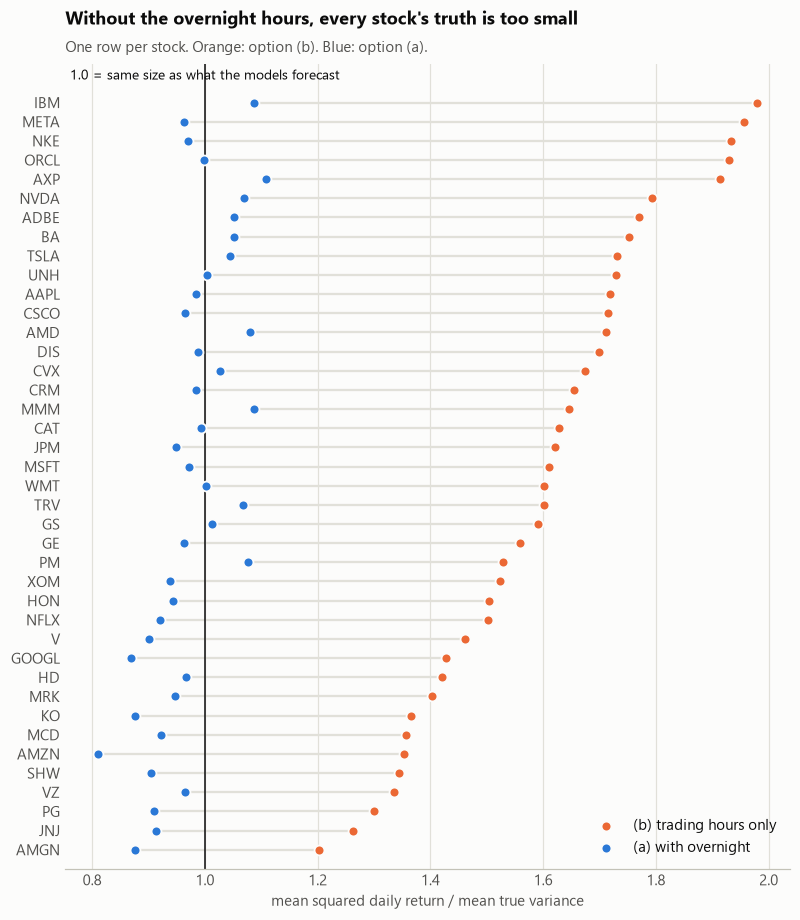

In [ ]:
overnight2 = panel.ret_overnight ** 2
panel["truth_b"] = panel.rv5_ss
panel["truth_a"] = panel.rv5_ss + overnight2
r2 = panel.ret ** 2

ratio_b, ratio_a = r2.mean() / panel.truth_b.mean(), r2.mean() / panel.truth_a.mean()
print("mean squared daily return / mean truth, all stocks together (1 = same hours)")
print(f"   (b) trading hours only : {ratio_b:.2f}")
print(f"   (a) with overnight     : {ratio_a:.2f}")

by = panel.assign(r2=r2).groupby("symbol")[["r2", "truth_a", "truth_b"]].mean()
ratio = pd.DataFrame({"(b) trading hours only": by.r2 / by.truth_b,
                      "(a) with overnight": by.r2 / by.truth_a}).sort_values("(b) trading hours only")
print("\nby stock:")
print(ratio.describe().loc[["min", "50%", "max"]].rename(index={"50%": "median"}).round(2).to_string())

fig, ax = plt.subplots(figsize=(8.5, 9.5))
y = np.arange(len(ratio))
ax.hlines(y, ratio["(a) with overnight"], ratio["(b) trading hours only"], color=GRID, lw=1.5, zorder=1)
ax.scatter(ratio["(b) trading hours only"], y, s=42, color=ORANGE, edgecolor=SURFACE, linewidth=1.2, zorder=3,
           label="(b) trading hours only")
ax.scatter(ratio["(a) with overnight"], y, s=42, color=BLUE, edgecolor=SURFACE, linewidth=1.2, zorder=3,
           label="(a) with overnight")
ax.axvline(1.0, color=INK, lw=1)
ax.text(1.0, len(ratio) + 0.2, "1.0 = same size as what the models forecast", color=INK, fontsize=9, ha="center")
ax.set_yticks(y, ratio.index)
ax.set_ylim(-1, len(ratio) + 1)
ax.set_xlabel("mean squared daily return / mean true variance", color=MUTED)
tidy(ax, "Without the overnight hours, every stock's truth is too small",
     "One row per stock. Orange: option (b). Blue: option (a).")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", frameon=False, labelcolor=INK)
fig.savefig(FIG / "dec2_ratio_by_stock.png", dpi=160, bbox_inches="tight")
plt.show()

numbers.update(ratio_b=float(ratio_b), ratio_a=float(ratio_a),
               ratio_b_min=float(ratio.iloc[:, 0].min()), ratio_b_max=float(ratio.iloc[:, 0].max()),
               ratio_a_min=float(ratio.iloc[:, 1].min()), ratio_a_max=float(ratio.iloc[:, 1].max()),
               ratio_a_med=float(ratio.iloc[:, 1].median()))

**What to notice.** Under (b) every orange dot sits to the right of 1: for every stock the real
close-to-close variance is bigger than this truth. A model that forecasts the close-to-close
variance *exactly right* would look as if it forecast far too much. Since the thesis asks whether
models forecast too *little*, option (b) would make the test measure the missing hours instead of
the model. Under (a) the blue dots scatter around 1.

**What (a) costs.** The overnight part is a single squared return per day, so it is noisy, and a
few very large overnight gaps weigh heavily. Meta's earnings night in February 2022 shows what
that looks like. The cell also checks that the dividend adjustment from section 3 did its job.

overnight share of the truth: typical day 12%, over the whole sample 39%
the 1% of days with the largest overnight moves hold 47% of all overnight variance
spread of the daily truth (std of its log): (a) 1.05   (b) 0.94

ex-dividend nights (1,465): median squared overnight move  raw 3.8e-05  dividend-adjusted 1.4e-05  |  an ordinary night 1.6e-05
change in total overnight variance from the adjustment: -0.33%


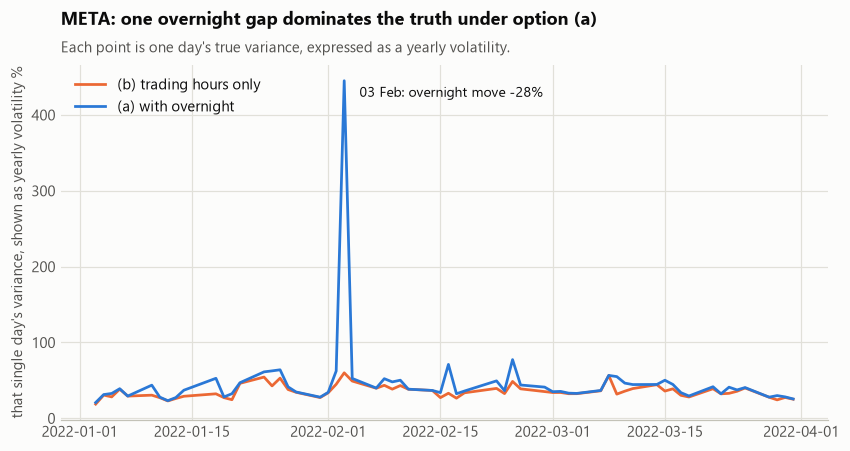

In [ ]:
share = overnight2 / panel.truth_a
top1 = overnight2.nlargest(len(panel) // 100).sum() / overnight2.sum()
print(f"overnight share of the truth: typical day {share.median():.0%}, over the whole sample {overnight2.sum() / panel.truth_a.sum():.0%}")
print(f"the 1% of days with the largest overnight moves hold {top1:.0%} of all overnight variance")
print(f"spread of the daily truth (std of its log): (a) {np.log(panel.truth_a).std():.2f}   (b) {np.log(panel.truth_b).std():.2f}")

exdiv = panel.dividend.fillna(0) > 0
raw_on = np.log(panel.open) - np.log(panel.groupby("symbol")["close"].shift(1))
print(f"\nex-dividend nights ({exdiv.sum():,}): median squared overnight move  raw {(raw_on[exdiv] ** 2).median():.1e}  "
      f"dividend-adjusted {(panel.ret_overnight[exdiv] ** 2).median():.1e}  |  an ordinary night {(panel.ret_overnight[~exdiv] ** 2).median():.1e}")
tot_change = (overnight2.sum() / (raw_on ** 2).sum() - 1)
print(f"change in total overnight variance from the adjustment: {tot_change:+.2%}")

SYMBOL, START, END = "META", "2022-01-03", "2022-03-31"
gg = panel[(panel.symbol == SYMBOL) & panel.date.between(START, END)]
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(gg.date, ann_vol(gg.truth_b), color=ORANGE, lw=1.8, label="(b) trading hours only")
ax.plot(gg.date, ann_vol(gg.truth_a), color=BLUE, lw=1.8, label="(a) with overnight")
top = gg.loc[gg.truth_a.idxmax()]
ax.annotate(f"{top.date:%d %b}: overnight move {100 * top.ret_overnight:+.0f}%", (top.date, ann_vol(top.truth_a)),
            xytext=(10, -4), textcoords="offset points", color=INK, fontsize=9, va="top")
ax.set_ylabel("that single day's variance, shown as yearly volatility %", color=MUTED)
tidy(ax, f"{SYMBOL}: one overnight gap dominates the truth under option (a)",
     "Each point is one day's true variance, expressed as a yearly volatility.")
ax.legend(loc="upper left", frameon=False, labelcolor=INK)
fig.savefig(FIG / "dec2_meta_gap.png", dpi=160, bbox_inches="tight")
plt.show()

numbers.update(on_share_typical=float(share.median()), on_share_total=float(overnight2.sum() / panel.truth_a.sum()),
               top1_share=float(top1), std_log_a=float(np.log(panel.truth_a).std()), std_log_b=float(np.log(panel.truth_b).std()),
               n_exdiv_panel=int(exdiv.sum()), exdiv_raw=float((raw_on[exdiv] ** 2).median()),
               exdiv_adj=float((panel.ret_overnight[exdiv] ** 2).median()), normal_night=float((panel.ret_overnight[~exdiv] ** 2).median()),
               total_on_change=float(tot_change), meta_date=f"{top.date:%d %B %Y}", meta_overnight=float(top.ret_overnight))

**Decision 2 = (a).** The truth is `rv5_ss` plus the squared overnight return, with the overnight
return measured from the ex-dividend close. The price is more noise, which is why the thesis
scores forecasts with losses that do not let a single huge day dominate (QLIKE, interval scores)
and reports plain squared error only as a robustness check. Recorded in `DECISIONS.md`, entry 2.

---
## 6. Decision 3: the earnings-night problem

The official close is 16:00. VOLARE's window runs to 16:05. Many companies publish results at
16:01, and the share price can jump 10 or 20 percent in those minutes. That jump lands in the
last five-minute return of the day, and therefore in that day's `rv5_ss`, although the market was
calm all day and the reaction really belongs to the *next* trading day.

**The flag.** A day is flagged when VOLARE's 16:05 price differs from the official 16:00 close by
more than 1 percent. The cell recomputes it and compares with the saved flag file
(`data/flags/volare_afterhours_flags.csv`), which is what the pipeline uses. A few days sit
exactly on the 1 percent line, where rounding in the official close decides; they are 1 percent
moves, not earnings jumps, so the choice does not matter. Netflix on 19 April 2022 is the biggest case.

In [ ]:
panel["after_hours"] = np.log(panel.close_price) - np.log(panel.close_official)     # move from 16:00 to 16:05
flag_recomputed = panel.after_hours.abs() > 0.01

# the pipeline uses the saved flag file (data/flags/), so from here on we do the same
saved = pd.read_csv(FLAGS, parse_dates=["date"])[["symbol", "date"]]
flag = pd.Series(pd.MultiIndex.from_frame(panel[["symbol", "date"]]).isin(pd.MultiIndex.from_frame(saved)), index=panel.index)
panel["earnings_afterclose"] = flag

print(f"flagged by recomputing: {int(flag_recomputed.sum())} | in the saved flag file: {int(flag.sum())} | in both: {int((flag & flag_recomputed).sum())}")
odd = panel.loc[flag != flag_recomputed, ["symbol", "date", "after_hours"]].assign(date=lambda d: d.date.dt.strftime("%Y-%m-%d"))
print("days where the two disagree, all sitting on the 1% line (rounding in the official close decides them):")
print(odd.assign(after_hours=(100 * odd.after_hours).round(3).astype(str) + "%").to_string(index=False))
print(f"\ntypical size of the 16:00-16:05 move on a flagged day: {panel.after_hours[flag].abs().median():.1%}")

ex = panel[(panel.symbol == "NFLX") & panel.date.between("2022-04-18", "2022-04-21")].copy()
ex["next overnight"] = ex.ret_overnight.shift(-1)
show = ex[["date", "close_official", "close_price", "after_hours", "next overnight"]].rename(
    columns={"close_official": "official close 16:00", "close_price": "VOLARE close 16:05", "after_hours": "move 16:00-16:05"})
for c in ["rv5_ss", "bv5_ss", "medrv5"]:
    show[f"{c} as yearly vol %"] = ann_vol(ex[c]).round(0)
show["date"] = show.date.dt.strftime("%Y-%m-%d")
print("\nNetflix, results published after the close on 19 April 2022:")
print(show.round(3).to_string(index=False))

d0 = ex.set_index("date").loc["2022-04-19"]
numbers.update(n_flag=int(flag.sum()), n_border=int(len(odd)), typical_5min_move=float(panel.after_hours[flag].abs().median()),
               nflx_official=float(d0.close_official), nflx_volare=float(d0.close_price), nflx_move=float(d0.after_hours),
               nflx_next_on=float(ex.set_index("date").loc["2022-04-20", "ret_overnight"]),
               nflx_rv_ann=float(ann_vol(d0.rv5_ss)), nflx_bv_ann=float(ann_vol(d0.bv5_ss)), nflx_med_ann=float(ann_vol(d0.medrv5)))

flagged by recomputing: 459 | in the saved flag file: 459 | in both: 458
days where the two disagree, all sitting on the 1% line (rounding in the official close decides them):
symbol       date after_hours
   AMD 2015-11-13        1.0%
  NFLX 2022-11-02     -0.998%

typical size of the 16:00-16:05 move on a flagged day: 2.0%

Netflix, results published after the close on 19 April 2022:
      date  official close 16:00  VOLARE close 16:05  move 16:00-16:05  next overnight  rv5_ss as yearly vol %  bv5_ss as yearly vol %  medrv5 as yearly vol %
2022-04-18                337.86             338.934             0.003          -0.014                    35.0                    33.0                    36.0
2022-04-19                348.61             284.882            -0.202          -0.352                   305.0                   114.0                    40.0
2022-04-20                226.19             225.890            -0.001          -0.028                   110.0                   113.0

**What to notice.** Netflix closed at 348.61 (official) and VOLARE's last price was 284.88: the
results knocked 20 percent off the share price between 16:00 and 16:05. The day's `rv5_ss` turns
into a yearly volatility of several hundred percent, while the two jump-robust measures stay
near normal. The next overnight move is another large negative number: that is the *same* news
continuing to be priced in.

### Is the news counted twice?

The overnight return runs from the official 16:00 close to the next open, so it already contains
whatever happened between 16:00 and 16:05. If that is true, the five-minute move on the flagged
day and the overnight move into the next day should point the same way.

same direction on 75% of the flagged days; correlation between the two moves 0.67


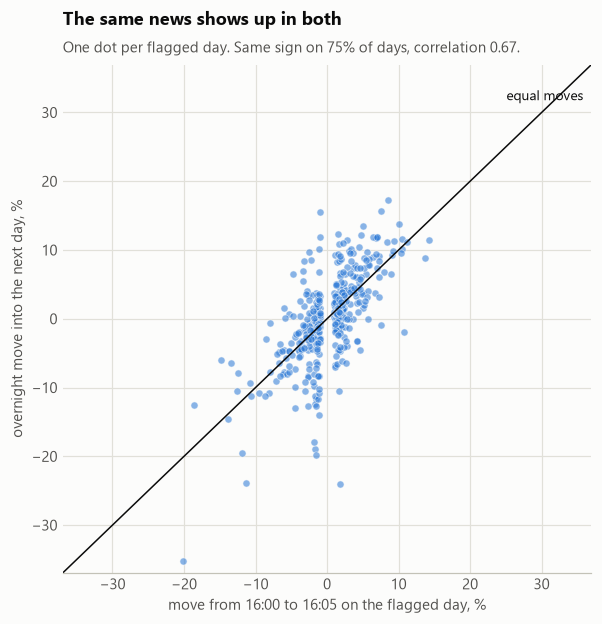

In [ ]:
panel["next_overnight"] = panel.groupby("symbol")["ret_overnight"].shift(-1)
x, yv = 100 * panel.after_hours[flag], 100 * panel.next_overnight[flag]
ok = x.notna() & yv.notna()
corr = np.corrcoef(x[ok], yv[ok])[0, 1]
same_sign = (np.sign(x[ok]) == np.sign(yv[ok])).mean()
print(f"same direction on {same_sign:.0%} of the flagged days; correlation between the two moves {corr:.2f}")

fig, ax = plt.subplots(figsize=(6.2, 6))
lim = float(np.nanmax(np.abs(np.r_[x[ok], yv[ok]]))) * 1.05
ax.plot([-lim, lim], [-lim, lim], color=INK, lw=1)
ax.text(lim * 0.97, lim * 0.86, "equal moves", color=INK, fontsize=9, ha="right")
ax.scatter(x[ok], yv[ok], s=22, color=BLUE, alpha=0.55, edgecolor=SURFACE, linewidth=0.6)
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_xlabel("move from 16:00 to 16:05 on the flagged day, %", color=MUTED)
ax.set_ylabel("overnight move into the next day, %", color=MUTED)
tidy(ax, "The same news shows up in both", f"One dot per flagged day. Same sign on {same_sign:.0%} of days, correlation {corr:.2f}.")
fig.savefig(FIG / "dec3_double_count.png", dpi=160, bbox_inches="tight")
plt.show()
numbers.update(same_sign=float(same_sign), corr_double=float(corr))

**What to notice.** The dots follow the line. Under option (a) of decision 2 the jump therefore
enters the truth twice: once on the flagged day through `rv5_ss`, once on the next day through
the overnight return. The fix is to take it out of the flagged day.

### Which measure takes it out?

VOLARE ships three ways of measuring a day's variance from the same five-minute returns:

- `rv5_ss`: the plain sum of squared returns. A jump counts in full.
- `bv5_ss`: *bipower variation*, built from products of neighbouring absolute returns. A lone jump
  is multiplied by a normal-sized neighbour, so it shrinks but does not vanish.
- `medrv5`: *median realised variance*, the median of each three neighbouring squared returns. A
  lone jump is never the median, so it disappears.

The chart lines up the eleven days around every flagged day and shows each measure relative to
the stock's normal `rv5_ss` (its median), so the three lines share one yardstick. The table adds
a fourth candidate: simply subtracting the squared five-minute move from `rv5_ss`.

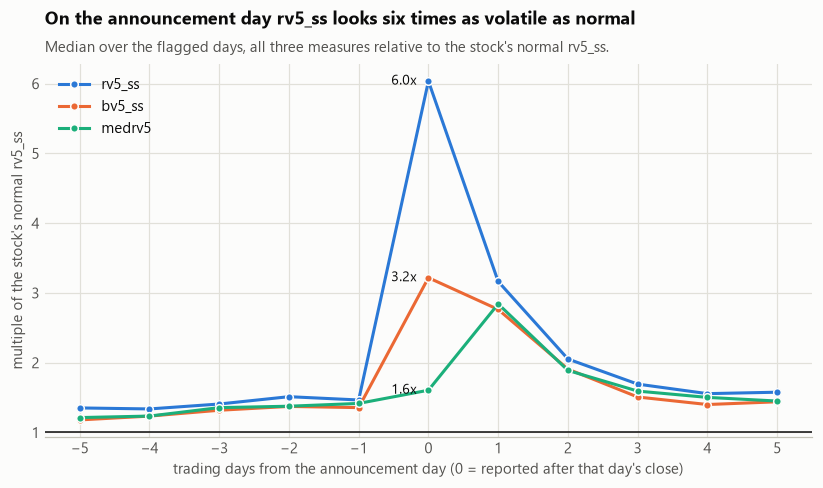

keep rv5_ss                               6.04
bv5_ss                                    3.22
rv5_ss minus the squared 5-minute move    2.19
medrv5                                    1.61

for comparison: day -2 1.51x, day -1 1.47x, day +1 3.16x
days where the squared 5-minute move is LARGER than the whole day's rv5_ss: 79 (subsampling smears the jump), so subtracting it is not well defined
on ordinary days medrv5 is 93% of rv5_ss


In [ ]:
measures = {"rv5_ss": BLUE, "bv5_ss": ORANGE, "medrv5": AQUA}
med = panel.groupby("symbol")["rv5_ss"].transform("median")          # the stock's normal level, same yardstick for all three
relative = panel[list(measures)].div(med, axis=0)
days = range(-5, 6)
around = pd.DataFrame({k: relative.groupby(panel.symbol).shift(-k)[flag].median() for k in days}).T
around.index.name = "days from the announcement"

fig, ax = plt.subplots(figsize=(9, 4.4))
for name, colour in measures.items():
    ax.plot(around.index, around[name], color=colour, lw=2, marker="o", ms=5, markeredgecolor=SURFACE, label=name)
    ax.annotate(f"{around.loc[0, name]:.1f}x", (0, around.loc[0, name]), xytext=(-8, 0), textcoords="offset points",
                color=INK, fontsize=9, ha="right", va="center")
ax.axhline(1.0, color=INK, lw=1)
ax.set_xticks(list(days))
ax.set_xlabel("trading days from the announcement day (0 = reported after that day's close)", color=MUTED)
ax.set_ylabel("multiple of the stock's normal rv5_ss", color=MUTED)
tidy(ax, "On the announcement day rv5_ss looks six times as volatile as normal",
     "Median over the flagged days, all three measures relative to the stock's normal rv5_ss.")
ax.legend(loc="upper left", frameon=False, labelcolor=INK)
fig.savefig(FIG / "dec3_window.png", dpi=160, bbox_inches="tight")
plt.show()

cands = {"keep rv5_ss": panel.rv5_ss, "bv5_ss": panel.bv5_ss,
         "rv5_ss minus the squared 5-minute move": np.maximum(panel.rv5_ss - panel.after_hours ** 2, panel.medrv5),
         "medrv5": panel.medrv5}
table = pd.Series({k: (v / med)[flag].median() for k, v in cands.items()}, name="announcement day, x normal (median)")
print(table.round(2).to_string())
n_over = int((panel.after_hours ** 2 > panel.rv5_ss)[flag].sum())
print(f"\nfor comparison: day -2 {around.loc[-2, 'rv5_ss']:.2f}x, day -1 {around.loc[-1, 'rv5_ss']:.2f}x, day +1 {around.loc[1, 'rv5_ss']:.2f}x")
print(f"days where the squared 5-minute move is LARGER than the whole day's rv5_ss: {n_over} "
      f"(subsampling smears the jump), so subtracting it is not well defined")
ordinary = (panel.medrv5 / panel.rv5_ss)[~flag].median()
print(f"on ordinary days medrv5 is {ordinary:.0%} of rv5_ss")
numbers.update(mult_rv=float(table.iloc[0]), mult_bv=float(table.iloc[1]), mult_strip=float(table.iloc[2]), mult_med=float(table.iloc[3]),
               mult_dm2=float(around.loc[-2, "rv5_ss"]), mult_dm1=float(around.loc[-1, "rv5_ss"]), mult_dp1=float(around.loc[1, "rv5_ss"]),
               n_over=n_over, med_ratio_ordinary=float(ordinary))

**Decision 3 = `medrv5` on the flagged days.** It puts the announcement day at about 1.6 times
normal, right beside the 1.5 of the two days before it, when traders were waiting for the
results. Bipower variation still shows the day at three times normal, and subtracting the
five-minute move is not well defined because the subsampled measure smears the jump over its
neighbours. Day +1 is left untouched in every variant: that is the market's real reaction during
trading hours. The cost is that `medrv5` runs about 7 percent below `rv5_ss` on an ordinary day,
on 459 of 117,280 rows. Recorded in `DECISIONS.md`, entry 3.

---
## 7. The finished truth and the market variables

Now we apply both decisions exactly as `config.yaml` states them, and add three market-wide
columns: the VIX level, the return of the IVV fund (a stand-in for the S&P 500), and a
market-wide realised variance, which is the typical `rv5_ss` across the 40 stocks on each day
(a geometric mean, because variances are best averaged on the log scale).

rows where the intraday part was replaced: 459
median daily truth 1.53e-04 = 19.6% yearly volatility
mean squared return / mean truth, all days: 1.008


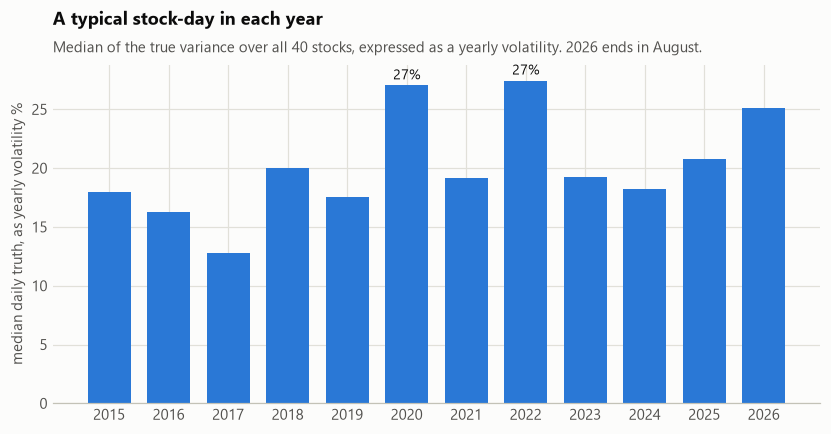

In [ ]:
t = cfg["target"]
replacement = {"keep": None, "flag_only": None, "bv5": "bv5_ss", "medrv5": "medrv5"}[t["earnings_days"]]
intraday = panel[t["intraday_measure"]]
if replacement is not None:
    intraday = panel[replacement].where(flag, intraday)
panel["rv_intraday_used"] = intraday
panel["rv_target"] = intraday + (overnight2 if t["add_overnight"] else 0.0)
panel["log_rv_target"] = np.log(panel.rv_target)

vix = yahoo[yahoo.symbol == cfg["sample"]["vix"]][["date", "close"]].rename(columns={"close": "vix"})
mkt = yahoo[yahoo.symbol == cfg["sample"]["market_proxy"]][["date", "ret"]].rename(columns={"ret": "mkt_ret"})
panel = panel.merge(vix, on="date", how="left").merge(mkt, on="date", how="left")
panel["mkt_rv"] = np.exp(panel.groupby("date")["rv5_ss"].transform(lambda s: np.log(s).mean()))

r2 = panel.ret ** 2
print(f"rows where the intraday part was replaced: {int((panel.rv_intraday_used != panel.rv5_ss).sum())}")
print(f"median daily truth {panel.rv_target.median():.2e} = {ann_vol(panel.rv_target.median()):.1f}% yearly volatility")
print(f"mean squared return / mean truth, all days: {r2.mean() / panel.rv_target.mean():.3f}")

by_year = panel.assign(year=panel.date.dt.year).groupby("year")["rv_target"].median().pipe(ann_vol)
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(by_year.index, by_year.values, width=0.72, color=BLUE)
for yr in (2020, 2022):
    ax.annotate(f"{by_year[yr]:.0f}%", (yr, by_year[yr]), xytext=(0, 4), textcoords="offset points", ha="center", color=INK, fontsize=9)
ax.set_xticks(list(by_year.index))
ax.set_ylabel("median daily truth, as yearly volatility %", color=MUTED)
tidy(ax, "A typical stock-day in each year", "Median of the true variance over all 40 stocks, expressed as a yearly volatility. 2026 ends in August.")
fig.savefig(FIG / "panel_vol_by_year.png", dpi=160, bbox_inches="tight")
plt.show()
numbers.update(target_med=float(panel.rv_target.median()), target_ann=float(ann_vol(panel.rv_target.median())),
               r2_over_target=float(r2.mean() / panel.rv_target.mean()),
               vol_2020=float(by_year[2020]), vol_2022=float(by_year[2022]), vol_calm=float(by_year[2017]))

---
## 8. Is it the same as the pipeline?

The real dataset is built by `python -m thesis.data.build_panel`, which reads the same settings
from `config.yaml`. If this notebook did everything right, the two tables must agree to rounding.

In [ ]:
ref = pd.read_parquet(PANEL).sort_values(["symbol", "date"]).reset_index(drop=True)
mine = panel.sort_values(["symbol", "date"]).reset_index(drop=True)
assert (ref.symbol.to_numpy() == mine.symbol.to_numpy()).all() and (ref.date.to_numpy() == mine.date.to_numpy()).all()

for c in ["ret", "ret_overnight", "ret_intraday", "rv_intraday_used", "rv_target", "log_rv_target", "vix", "mkt_ret", "mkt_rv"]:
    same = np.allclose(ref[c].to_numpy(), mine[c].to_numpy(), equal_nan=True, rtol=1e-9, atol=1e-12)
    print(f"{c:18s} {'identical' if same else 'DIFFERENT'}")
print(f"{'earnings flag':18s} {'identical' if (ref.earnings_afterclose.to_numpy() == mine.earnings_afterclose.to_numpy()).all() else 'DIFFERENT'}")

ret                identical
ret_overnight      identical
ret_intraday       identical
rv_intraday_used   identical
rv_target          identical
log_rv_target      identical
vix                identical
mkt_ret            identical
mkt_rv             identical
earnings flag      identical


---
## 9. Features and the no-look-ahead rule

A forecast made at the end of day *t* may only use information available by then. So every
**feature** is built from day *t* and earlier (for example the average log variance over the last
1, 5 and 22 days, the inputs of the HAR model), while the **target** is built from day *t+1*
onwards:

- `y_h1`: the log of tomorrow's true variance.
- `y_h20`: the log of the average true variance over the next 20 trading days.

The table shows one week of Apple around the Covid crash, then checks the columns against the
pipeline's feature table (`python -m thesis.features`).

In [ ]:
a = mine[mine.symbol == "AAPL"].set_index("date")
log_rv = np.log(a.rv_target)
demo = pd.DataFrame({
    "log_rv today": log_rv,
    "mean last 1d": log_rv.rolling(1).mean(),
    "mean last 5d": log_rv.rolling(5).mean(),
    "mean last 22d": log_rv.rolling(22).mean(),
    "y_h1 (tomorrow)": np.log(a.rv_target.shift(-1)),
    "y_h20 (next 20 days)": np.log(a.rv_target.shift(-1).rolling(20).mean().shift(-19)),
})
print("Apple, March 2020 (values are log variances; more negative = calmer):")
print(demo.loc["2020-03-09":"2020-03-13"].round(2).to_string())

feat = pd.read_parquet(FEATURES)
fa = feat[feat.symbol == "AAPL"].set_index("date")
for mine_c, pipe_c in [("mean last 5d", "log_rv_m5"), ("mean last 22d", "log_rv_m22"), ("y_h1 (tomorrow)", "y_h1"), ("y_h20 (next 20 days)", "y_h20")]:
    same = np.allclose(demo[mine_c].to_numpy(), fa[pipe_c].to_numpy(), equal_nan=True)
    print(f"{pipe_c:12s} matches the pipeline: {same}")

with open(FIG / "data_prep_numbers.json", "w", encoding="utf-8") as fh:
    json.dump(numbers, fh, indent=1)
print(f"\nsaved {len(numbers)} key numbers to {FIG / 'data_prep_numbers.json'}")

Apple, March 2020 (values are log variances; more negative = calmer):
            log_rv today  mean last 1d  mean last 5d  mean last 22d  y_h1 (tomorrow)  y_h20 (next 20 days)
date                                                                                                      
2020-03-09         -4.54         -4.54         -6.04          -7.45            -5.78                 -5.59
2020-03-10         -5.78         -5.78         -6.03          -7.29            -6.46                 -5.61
2020-03-11         -6.46         -6.46         -5.95          -7.18            -4.55                 -5.63
2020-03-12         -4.55         -4.55         -5.49          -7.04            -4.85                 -5.78
2020-03-13         -4.85         -4.85         -5.23          -6.85            -3.79                 -5.91
log_rv_m5    matches the pipeline: True
log_rv_m22   matches the pipeline: True
y_h1         matches the pipeline: True
y_h20        matches the pipeline: True

saved 69 key numbers

---
## 10. Glossary

| Term | Meaning |
|---|---|
| Log return | `log(P_t / P_t-1)`. Nearly the percentage change; adds up over days. |
| Variance | Average squared deviation of returns; the quantity the thesis forecasts. |
| Volatility | Square root of the variance; the same units as a return. Yearly = daily x sqrt(252). |
| Realised variance (RV) | A day's variance measured from inside the day: the sum of squared five-minute returns. |
| `_ss` (subsampled) | The measure averaged over several shifted five-minute grids; less noisy. |
| Bipower variation (`bv`) | Sum of products of neighbouring absolute returns; shrinks jumps. |
| Median RV (`medrv`) | Median of each three neighbouring squared returns; removes a lone jump. |
| Realised quarticity (`rq`) | How noisy the day's RV itself is; used later by the HARQ model. |
| Semivariances (`rsp`, `rsn`) | RV from positive and from negative five-minute returns separately. |
| Overnight / intraday | Close-to-open / open-to-close parts of a daily return. |
| Ex-dividend day | The day a dividend leaves the share price; the open is quoted without it. |
| Adjusted close | Price corrected for splits and dividends; the right basis for returns. |
| Panel | A table with one row per (stock, day). "Balanced" = every stock has every day. |
| Parquet | A compact binary table format; faster and smaller than CSV. |
| Look-ahead | Using information from after the forecast date; the error to avoid. |